# Datory Lab 트랙 B — 부산 해안 CCTV 가시커버리지·배치 최적화

지금까지의 분석을 순서대로 재현합니다.

| 단계 | 스크립트 | 내용 |
|---|---|---|
| 1 | `reanalyze_cctv_coverage.py` | 행안부·ITS·재난예경보·교통 API CCTV 통합 (20m 중복 제거, 12,808지점), 500m 반경 공백률 |
| 2 | `attach_cctv_fov.py` | 통합 지점에 행안부 촬영방면정보(화각) 결합 |
| 3 | `fetch_dem_copernicus.py` | Copernicus GLO-30 DSM 부산 범위 (압축파일에 포함됨, 선택적으로 다시 받기) |
| 4 | `prepare_viewshed.py` | 관측점·분석 대상구역(해안 ±100m)·가정값 생성 |
| 5 | `run_viewshed.py` | 전체 viewshed, 구간·구별 가시 커버율 / 사각지대 |
| 6 | `viewshed_sensitivity.py` | 화각·방위각·높이·가시거리 민감도, 시나리오 ① 방향 조정 |
| 7 | `viewshed_new_sites.py` | 시나리오 ② 신규 N대 균등 배치 (신규 후보지에서 섬 제외) |
| 7-1 | `build_trackD_dataset.py --weights-only`, `viewshed_new_sites.py --weights` | 트랙 D 가중치(위험지수, 섬 0)로 위험도 가중 배치 |
| 8 | `export_segment_results.py`, `build_trackD_dataset.py`, `trackA_compare_plans.py` | 구간별 결과 CSV, 트랙 D 구간표·설치후보 v4, 두 배치안 비교 |
| 9 | `plot_viewshed_maps.py` | 사각지대·신규 배치 지도 (섬 회색), 설치후보·위험도 배치 지도 |

**준비:** `DatoryLab_trackB_colab.zip`을 Google Drive의 `MyDrive/DatoryLab/` 또는 `MyDrive/Colab Notebooks/DatoryLab/`에 올리세요. 없으면 아래 셀에서 직접 업로드할 수 있습니다.

## 0. 패키지와 한글 글꼴 설치

In [42]:
%pip install -q "geopandas>=1.0,<2" "pyogrio>=0.10" "rasterio>=1.3" "folium>=0.18" "matplotlib>=3.8"
!apt-get -qq install -y fonts-nanum > /dev/null
!rm -rf ~/.cache/matplotlib

Note: you may need to restart the kernel to use updated packages.
E: Could not open lock file /var/lib/dpkg/lock-frontend - open (13: Permission denied)
E: Unable to acquire the dpkg frontend lock (/var/lib/dpkg/lock-frontend), are you root?


## 0-1. 데이터 압축파일 불러오기

In [43]:
# [0-1번 셀 로컬 대체 코드] 기존 DatoryLab_trackB는 보존하고 DatoryLab_trackB_2 폴더로 독립 실행
import zipfile, os, shutil
from pathlib import Path

BASE_DIR = Path('/home/alsgu/datory_work') if Path('/home/alsgu/datory_work').exists() else Path.cwd()
if BASE_DIR.name in ('DatoryLab_trackB', 'DatoryLab_trackB_2'):
    BASE_DIR = BASE_DIR.parent

zip_path = BASE_DIR / 'DatoryLab_trackB_2_colab.zip'
WORK = BASE_DIR / 'DatoryLab_trackB_2'

if zip_path.exists():
    shutil.rmtree(WORK, ignore_errors=True)
    with zipfile.ZipFile(zip_path) as zf:
        zf.extractall(BASE_DIR)

# 추가한 행정안전부 연안사고 CSV도 DatoryLab_trackB_2 작업 폴더 안으로 복사
acc_csv = BASE_DIR / '부산전체_행정안전부_연안사고.csv'
if acc_csv.exists():
    shutil.copy(acc_csv, WORK / '부산전체_행정안전부_연안사고.csv')

os.chdir(WORK)
print('작업 폴더 이동 완료 (기존 DatoryLab_trackB 보존):', Path.cwd())


작업 폴더 이동 완료 (기존 DatoryLab_trackB 보존): /home/alsgu/datory_work/DatoryLab_trackB_2


## 1. CCTV 통합과 500m 반경 공백률

기존 교통 CCTV 238대만 쓰면 공백 84.8%이고, 4개 출처를 통합하면 29.4%입니다.

In [44]:
!python tools/reanalyze_cctv_coverage.py > /dev/null
import pandas as pd
pd.set_option('display.width', 200)
display(pd.read_csv('outputs/cctv_reanalysis/cctv_reanalysis_summary.csv', encoding='utf-8-sig'))
display(pd.read_csv('outputs/cctv_reanalysis/cctv_deduplication_report.csv', encoding='utf-8-sig'))

,metric,value
0,기존 교통 CCTV 위치,238.0
1,행안부 원본 행,18074.0
2,행안부 유효 좌표 행,18054.0
3,행안부 좌표 무효 행,20.0
4,행안부 고유 설치지점,12429.0
5,행안부 카메라 대수 합,26840.0
6,부산 ITS 위치,315.0
7,부산 재난예경보 CCTV 행,81.0
8,통합 고유 CCTV 위치,12808.0
9,분석 해안구간,1832.0


,source,input_locations,duplicates_within_20m,new_locations_added,median_duplicate_distance_m
0,BUSAN_ITS_2026,315,21,294,11.27
1,BUSAN_TRAFFIC_API_EXISTING,238,214,24,0.00
2,DISASTER_WARNING_CCTV,81,20,61,9.81


## 2. 통합 지점에 화각(촬영방면정보) 붙이기

In [45]:
!python tools/attach_cctv_fov.py

saved /home/alsgu/datory_work/DatoryLab_trackB_2/outputs/cctv_reanalysis/cctv_integrated_locations_fov.csv (12,808 rows)
view_type
unknown    8344
ptz_360    3193
fixed      1271
view_type  fov_deg_max
fixed      NaN             883
           60.0            216
           90.0            172
ptz_360    360.0          3193
unknown    NaN            8344


## 3. DEM (Copernicus GLO-30 DSM, 30m)

압축파일에 이미 들어 있습니다. 새로 받으려면 `DOWNLOAD_DEM = True`로 바꾸세요(AWS 공개 버킷에서 부산 범위만 읽습니다).

In [46]:
DOWNLOAD_DEM = False
if DOWNLOAD_DEM:
    !python tools/fetch_dem_copernicus.py
import rasterio
with rasterio.open('data/raw/dem/busan_copernicus_dsm30_5186.tif') as src:
    print(src.crs, src.width, 'x', src.height, src.res)

EPSG:5186 1828 x 1849 (30.0, 30.0)


## 4. Viewshed 입력 준비 (기존 해안 인접 CCTV 1,782곳 3분류 차등 반영)

기존에는 해안 400m 이내의 모든 CCTV(1,782곳)가 가장 가까운 해안선을 정면 직시하고 화각 미상은 360°라고 일괄 가정했으나, 실제 데이터(3D 지형 차폐·화각·설치목적·해안거리)에 근거하여 아래와 같이 **3분류(6세부유형)**로 현실화하여 해안선 구간 가시 커버율을 산정합니다.

| 분류 구분 | 세부 조건 | 대수 | 비율 | 소계 | 가시권(Viewshed) 반영 기준 |
| :--- | :--- | :---: | :---: | :---: | :--- |
| **🟢 1. 해양을 확실히 봄** | 지형 가시(`omni>0`) + **360° 회전형(`ptz_360`)** (방범·다목적·재난 등) | 516곳 | 29.0% | **665곳 (37.3%)** | **100% 반영** (360° 전방위) |
| | 지형 가시(`omni>0`) + **`재난재해`·`시설물관리`** 목적 (고정/미상) | 149곳 | 8.4% | | **100% 반영** (최근접 해안 직시, 고정 60°/90°) |
| **🟡 2. 어느 정도(조건부) 봄** | 지형 가시(`omni>0`) + 고정/미상 + **해안 50m 이내 초근접** (해변로·해안로) | 137곳 | 7.7% | **867곳 (48.7%)** | **해안방향 고정 60°** 반영 |
| | 지형 가시(`omni>0`) + 고정/미상 + **해안 50~400m 내륙** (방향 미상) | 730곳 | 41.0% | | **해안 직시 해제** (비스듬한 +60° 오프셋·고정 60° 부분 반영) |
| **🔴 3. 전혀 보고 있지 않음** | **3D 지형 완전 차폐 (`omni == 0ha`)** — 언덕·산에 막혀 바다 안 보임 | 124곳 | 7.0% | **250곳 (14.0%)** | **완전 제외 (0%)** |
| | **`어린이보호`(스쿨존)** 및 **`교통단속`(차선·번호판 전용)** | 126곳 | 7.1% | | **완전 제외 (0%)** |
| **합계** | 해안 가시권 도달 가능 범위(`can_reach_zone == True`) 전체 | **1,782곳** | **100.0%** | **1,782곳 (100%)** | 부산 전체 커버율: 기존 `38.6%` → **3분류 반영 `25.1%`** |


In [47]:
import os, json
from pathlib import Path
if Path.cwd().name != 'DatoryLab_trackB_2' and Path('/home/alsgu/datory_work/DatoryLab_trackB_2').exists():
    os.chdir('/home/alsgu/datory_work/DatoryLab_trackB_2')

!python tools/prepare_viewshed.py 2>&1 | grep -v Warning
obs_df = pd.read_csv("outputs/viewshed/viewshed_observers.csv", encoding="utf-8-sig")
reach_df = obs_df[obs_df["can_reach_zone"] == True]
summary_3grp = (
    reach_df.groupby(["ocean_view_group", "ocean_view_detail"])
    .size()
    .reset_index(name="대수")
)
summary_3grp["비율(%)"] = (summary_3grp["대수"] / len(reach_df) * 100).round(1)
display(summary_3grp)


  return lib.distance(a, b, **kwargs)
ICCTV_00168 ptz_360 fov=360 az=56 visible=14.67ha in_zone=7.56ha (0.01s)
ICCTV_00181 fixed fov=90 az=116 visible=6.12ha in_zone=4.41ha (0.00s)
observers 3,856 (of 12,808 sites within 1000m)
can reach target zone 1,782
can_reach_zone  False  True 
view_type                   
fixed             248    265
ptz_360           640    583
unknown          1186    934

[전체 1,782개 해안 관측 CCTV 3분류 요약]
ocean_view_group   ocean_view_detail                
🔴 3. 전혀 보고 있지 않음   3-1. 3D 지형 완전 차폐 (omni == 0ha)       124
                   3-2. 어린이보호(스쿨존)·교통단속(차선 전용)          126
🟡 2. 어느 정도(조건부) 봄  2-1. 지형 가시 + 해안 50m 이내 초근접           137
                   2-2. 지형 가시 + 해안 50~400m 거리(방향 미상)    730
🟢 1. 해양을 확실히 봄     1-1. 지형 가시 + 360° 회전형(ptz_360)       516
                   1-2. 지형 가시 + 재난재해·시설물관리 목적           149
fov assumed 2,586 / target zone 58.74 km2


,ocean_view_group,ocean_view_detail,대수,비율(%)
0,🔴 3. 전혀 보고 있지 않음,3-1. 3D 지형 완전 차폐 (omni == 0ha),124,7.0
1,🔴 3. 전혀 보고 있지 않음,3-2. 어린이보호(스쿨존)·교통단속(차선 전용),126,7.1
2,🟡 2. 어느 정도(조건부) 봄,2-1. 지형 가시 + 해안 50m 이내 초근접,137,7.7
3,🟡 2. 어느 정도(조건부) 봄,2-2. 지형 가시 + 해안 50~400m 거리(방향 미상),730,41.0
4,🟢 1. 해양을 확실히 봄,1-1. 지형 가시 + 360° 회전형(ptz_360),516,29.0
5,🟢 1. 해양을 확실히 봄,1-2. 지형 가시 + 재난재해·시설물관리 목적,149,8.4


## 5. 전체 viewshed — 구·군별 가시 커버율과 사각지대

In [48]:
!python tools/run_viewshed.py 2>&1 | grep -E "done|segments with"
display(pd.read_csv('outputs/viewshed/viewshed_by_district.csv', encoding='utf-8-sig', index_col=0))

done 1,782 observers in 32s
segments with zero visible area (current, area>0): 889 / 1,765 (zero-area 67)


,segments,zone_ha,covered_ha_current,covered_ha_omni,coverage_pct_current,coverage_pct_omni,rotate_gain_pp
부산광역시 강서구,460.0,1886.5,234.5,566.9,12.4,30.1,17.7
부산광역시 기장군,502.0,808.0,462.1,484.8,57.2,60.0,2.8
부산광역시 남구,118.0,492.8,74.2,157.1,15.1,31.9,16.8
부산광역시 동구,23.0,147.3,21.0,45.2,14.2,30.7,16.5
부산광역시 사하구,336.0,1195.6,145.8,271.2,12.2,22.7,10.5
부산광역시 서구,56.0,259.0,101.1,104.6,39.0,40.4,1.4
부산광역시 수영구,22.0,117.8,117.4,117.5,99.6,99.8,0.2
부산광역시 영도구,178.0,599.2,160.0,258.8,26.7,43.2,16.5
부산광역시 중구,19.0,93.9,49.1,50.0,52.3,53.2,0.9
부산광역시 해운대구,118.0,273.4,109.1,212.4,39.9,77.7,37.8


## 6. 민감도 분석 · 시나리오 ① 방향만 조정

기존 CCTV 3분류 기준(그룹3 250곳 제외, 그룹1·2 반영)에서 고정형 카메라들의 방향(해안 반대·무작위 30회·3분류 기본·방향 최적화)별 커버율입니다. (약 1분)

In [49]:
!python tools/viewshed_sensitivity.py 2>&1 | grep -E "^[0-9]/|done|:"
display(pd.read_csv('outputs/viewshed/sensitivity_fov_azimuth.csv', encoding='utf-8-sig'))
display(pd.read_csv('outputs/viewshed/sensitivity_height_range.csv', encoding='utf-8-sig'))

1/3 기준 가시 셀 계산
2/3 화각·방위각 시나리오
  3분류기본(미상=고정60°): done
  미상=고정60°: done
  미상=고정90°: done
3/3 높이·가시거리 시나리오
  기준 (6/8m, 300m): 25.1%
  높이 -2m (4/6m): 24.05%
  높이 +2m (8/10m): 25.87%
  가시거리 200m: 17.75%
  가시거리 500m: 35.12%


,unknown_fov,fixed_cameras,away_from_coast_pct,random_mean_pct,random_min_pct,random_max_pct,toward_coast_pct,optimized_pct,gain_from_random_pp,gain_from_away_pp,zero_segments_random_mean,zero_segments_optimized
0,3분류기본(미상=고정60°),1016,16.41,23.02,22.33,23.61,25.10,31.98,8.96,15.57,932.0,804
1,미상=고정60°,1016,16.41,22.99,22.34,23.55,25.10,31.98,8.99,15.57,930.3,804
2,미상=고정90°,1016,18.57,26.15,25.53,27.13,28.61,34.19,8.04,15.62,887.6,793


,scenario,observers,coverage_pct,covered_ha,zero_segments
0,"기준 (6/8m, 300m)",1782,25.10,1474.1,889
1,높이 -2m (4/6m),1782,24.05,1412.6,898
2,높이 +2m (8/10m),1782,25.87,1519.3,878
3,가시거리 200m,1378,17.75,1042.6,1032
4,가시거리 500m,2525,35.12,2062.9,754


## 7. 시나리오 ② 신규 N대 균등 배치

모든 구간을 같은 비중으로 두고 신규 카메라를 배치합니다. 신규 후보지는 해안선 60m 안쪽 **육지부**만 씁니다. 섬(도서부)과 `data/raw/manual_site_exclusions.csv`의 수동 제외 구간(거가대교 터널 구간 섬, 위성사진으로 판정한 항만 보안·작업 구역 29구간)은 뺍니다.
다른 가중치 파일을 쓰려면 `WEIGHTS`에 경로를 넣으세요(`segment_id,weight`).

In [50]:
N_NEW = 200
WEIGHTS = ''   # 예: 'outputs/trackD/trackB_weights.csv'
args = f'--n {N_NEW}' + (f' --weights {WEIGHTS}' if WEIGHTS else '')
!python tools/viewshed_new_sites.py {args} 2>&1 | grep -E "^[0-9]/|후보|total"
suffix = '' if not WEIGHTS else '_' + Path(WEIGHTS).stem
display(pd.read_csv(f'outputs/viewshed/new_sites_curve{suffix}.csv', encoding='utf-8-sig'))
display(pd.read_csv(f'outputs/viewshed/new_sites_top50_by_district{suffix}.csv', encoding='utf-8-sig'))

1/4 기존 CCTV 커버(기준선)
2/4 후보지 생성·가시영역 계산
   후보 1,775개 (50s)
3/4 그리디 배치
4/4 저장
total 50s


,weights,baseline,new_cameras,coverage_pct,weighted_coverage_pct,added_ha,zero_segments
0,uniform,conservative_after_rotation,0,31.98,31.98,0.0,804
1,uniform,conservative_after_rotation,5,34.03,34.03,120.3,779
2,uniform,conservative_after_rotation,10,35.68,35.68,217.3,749
3,uniform,conservative_after_rotation,20,38.64,38.64,391.1,689
4,uniform,conservative_after_rotation,30,41.20,41.20,541.1,644
5,uniform,conservative_after_rotation,50,45.61,45.61,800.1,566
6,uniform,conservative_after_rotation,100,54.86,54.86,1343.4,413
7,uniform,conservative_after_rotation,150,61.85,61.85,1753.9,303
8,uniform,conservative_after_rotation,200,67.08,67.08,2061.6,237
9,uniform,original_360,0,25.10,25.10,0.0,889


,SGG_NAM,conservative_after_rotation,original_360
0,부산광역시 강서구,12,11
1,부산광역시 기장군,9,7
2,부산광역시 남구,6,5
3,부산광역시 동구,3,3
4,부산광역시 사하구,12,13
5,부산광역시 서구,2,2
6,부산광역시 영도구,3,5
7,부산광역시 중구,2,2
8,부산광역시 해운대구,1,2


## 7-1. 위험도 가중 배치 (트랙 D 가중치)

`trackB_weights.csv` = 트랙 A 위험지수(√(유형위험 × 파랑노출)), **섬(도서부)과 수동 제외 구간(합계 368구간)은 0**. 트랙 A 산출물(`data/raw/trackA/track_a_csvs_20261014/`)과 해안선 육지부/도서부 구분(`GRP_ISL`)으로 만듭니다.
`trackA_reevaluate.py`는 트랙 A 3차본 설치후보(63구간)의 재분류 기록용입니다.

In [51]:
!python tools/trackA_reevaluate.py 2>&1 | grep -E "후보|통합"
!python tools/build_trackD_dataset.py --weights-only 2>&1 | grep saved
!python tools/viewshed_new_sites.py --weights outputs/trackD/trackB_weights.csv 2>&1 | grep -E "후보|total"
display(pd.read_csv('outputs/viewshed/new_sites_curve_trackB_weights.csv', encoding='utf-8-sig'))
display(pd.read_csv('outputs/viewshed/new_sites_top50_by_district_trackB_weights.csv', encoding='utf-8-sig'))

후보 63구간, 위험지수 = sqrt(T×W) 확인: 0.0
통합 CCTV 500m 이내 없음: 42 / 63
saved trackB_weights.csv (nonzero 1464, excluded 0: 368)
2/4 후보지 생성·가시영역 계산
   후보 1,775개 (50s)
total 50s


,weights,baseline,new_cameras,coverage_pct,weighted_coverage_pct,added_ha,zero_segments
0,trackB_weights,conservative_after_rotation,0,31.98,45.59,0.0,804
1,trackB_weights,conservative_after_rotation,5,33.65,48.90,97.9,776
2,trackB_weights,conservative_after_rotation,10,35.01,51.27,177.5,758
3,trackB_weights,conservative_after_rotation,20,37.47,55.33,322.3,736
4,trackB_weights,conservative_after_rotation,30,39.97,58.60,469.1,676
5,trackB_weights,conservative_after_rotation,50,43.95,63.89,702.7,597
6,trackB_weights,conservative_after_rotation,100,52.49,73.34,1204.6,458
7,trackB_weights,conservative_after_rotation,150,60.07,79.83,1649.7,343
8,trackB_weights,conservative_after_rotation,200,64.96,84.47,1936.6,286
9,trackB_weights,original_360,0,25.10,37.07,0.0,889


,SGG_NAM,conservative_after_rotation,original_360
0,부산광역시 강서구,3,2
1,부산광역시 기장군,14,14
2,부산광역시 남구,8,7
3,부산광역시 동구,4,5
4,부산광역시 사하구,5,6
5,부산광역시 서구,4,3
6,부산광역시 영도구,8,7
7,부산광역시 중구,2,2
8,부산광역시 해운대구,2,4


## 8. 구간별 결과 CSV · 트랙 D 구간표 · 두 배치안 비교

- `outputs/input_trackB_segments.csv`(트랙 D 입력용 영문판), `outputs/segment_results_busan.csv`(한글판)
- `outputs/trackD/segments.csv`(트랙 A 위험지수 + 트랙 B CCTV·가시 커버율, 1,832행), `cctv_candidates_v4.csv`(위험등급 4·5 + 설치 대상 + 보수적 커버율 0%), `validation.json`
- `outputs/trackD/plan_comparison.csv`: 신규 10·20·50대일 때 해안 전체 / 위험지수 가중 / 설치후보 v4 커버율

In [52]:
!python tools/export_segment_results.py 2>&1 | grep saved
!python tools/build_trackD_dataset.py 2>&1 | grep -E "candidates|constant|island|rows"
!python tools/trackA_compare_plans.py 2>&1 | grep -v Warning
!python tools/trackD_query.py SEG_000492

saved /home/alsgu/datory_work/DatoryLab_trackB_2/outputs/segment_results_busan.csv (1,832 rows, 24 cols)
  "segments_rows": 1832,
  "constant_columns": [],
  "island_segments": 325,
  "candidates_v4": 34,
  "candidates_trackA_v3": 63,
  "candidates_kept": 33,
  "candidates_added": [
  "candidates_dropped": [
     plan  new_cameras  coast_coverage_pct  risk_weighted_coverage_pct  candidates_v4_coverage_pct
    균등 배치           10                35.7                        49.7                        17.5
    균등 배치           20                38.6                        53.1                        28.5
    균등 배치           50                45.6                        60.7                        47.8
위험도 가중 배치           10                35.0                        51.3                        37.6
위험도 가중 배치           20                37.5                        55.3                        46.7
위험도 가중 배치           50                43.9                        63.9                        61

## 9. 지도 — 사각지대와 신규 설치 우선지점

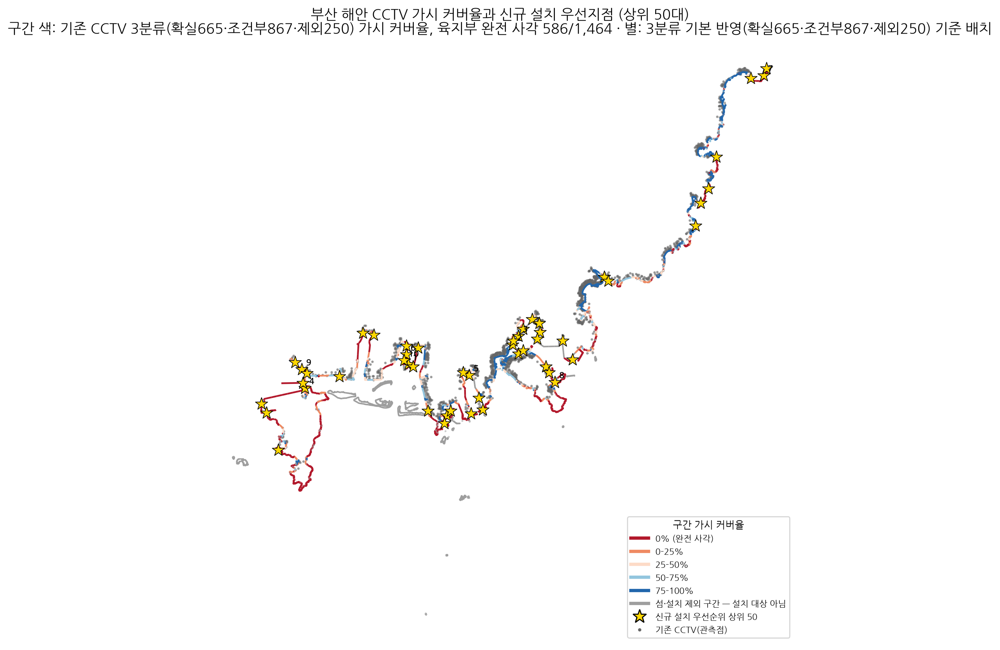

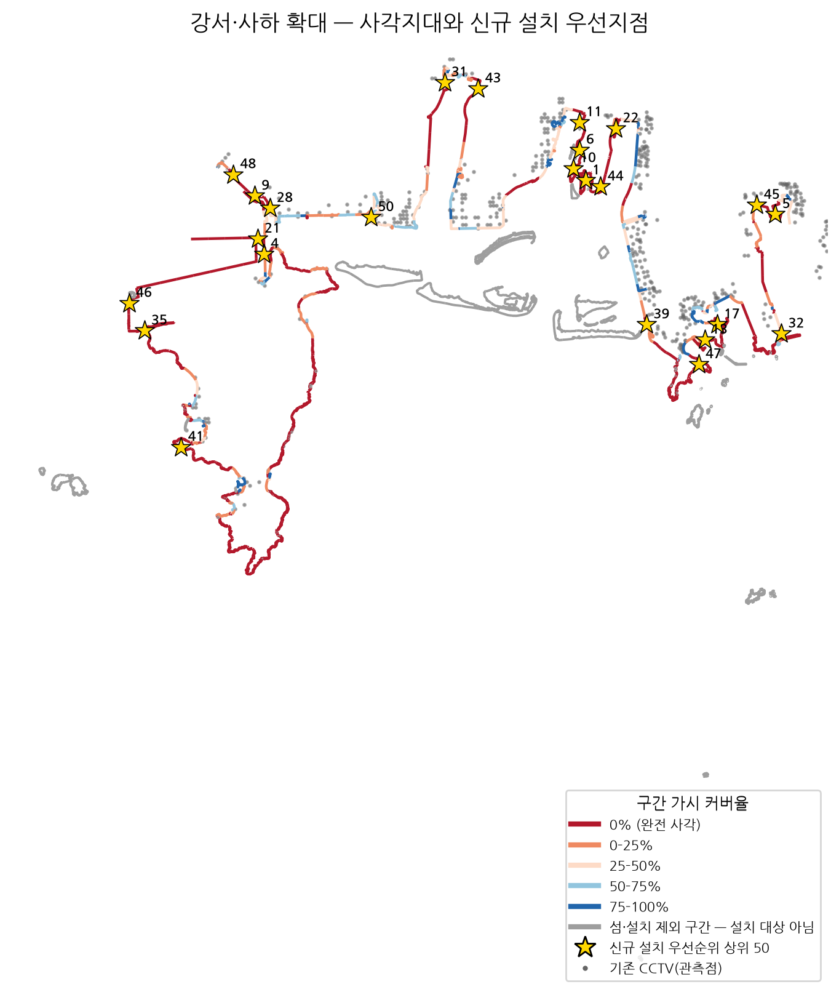

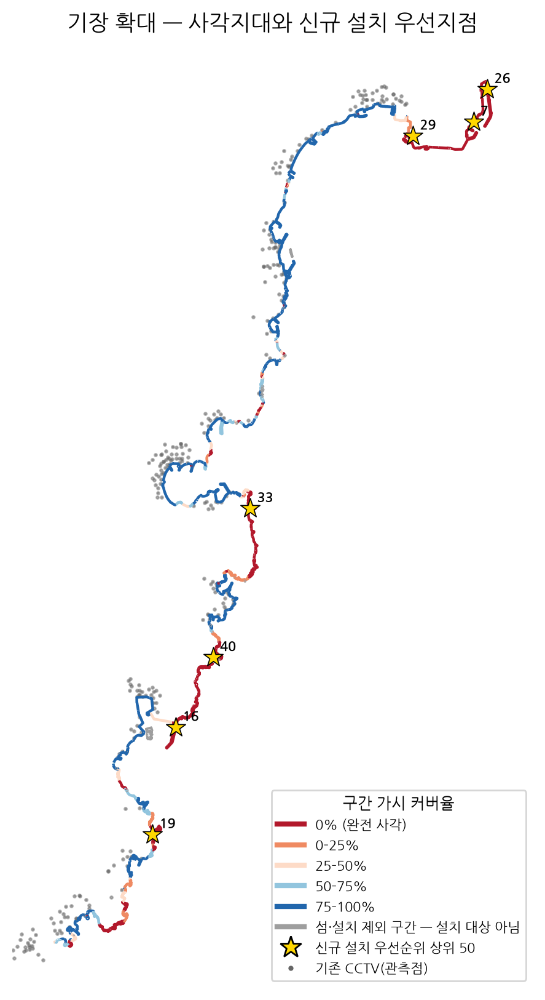

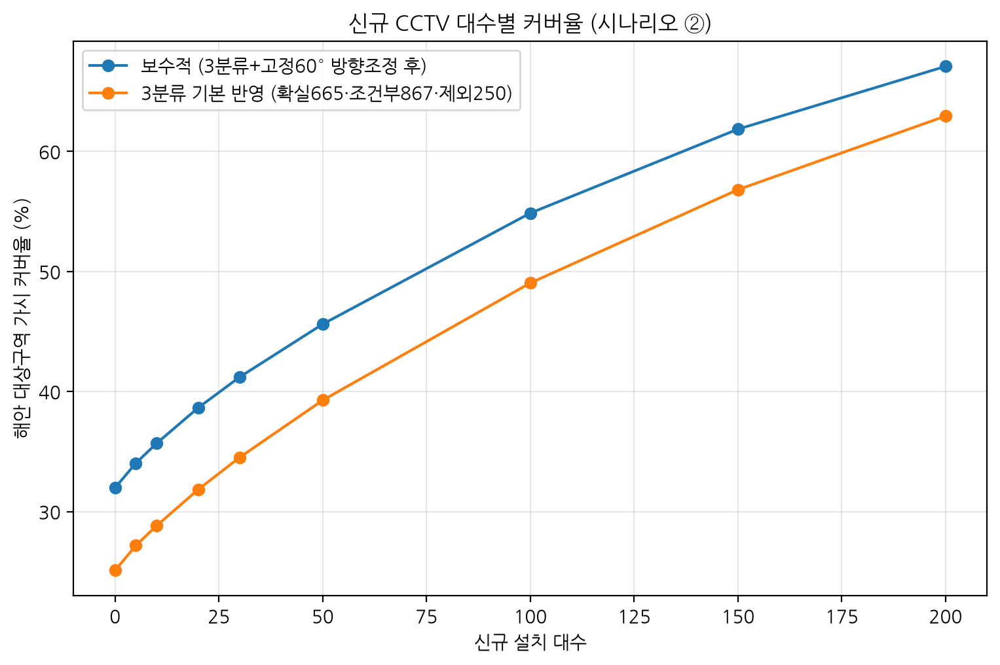

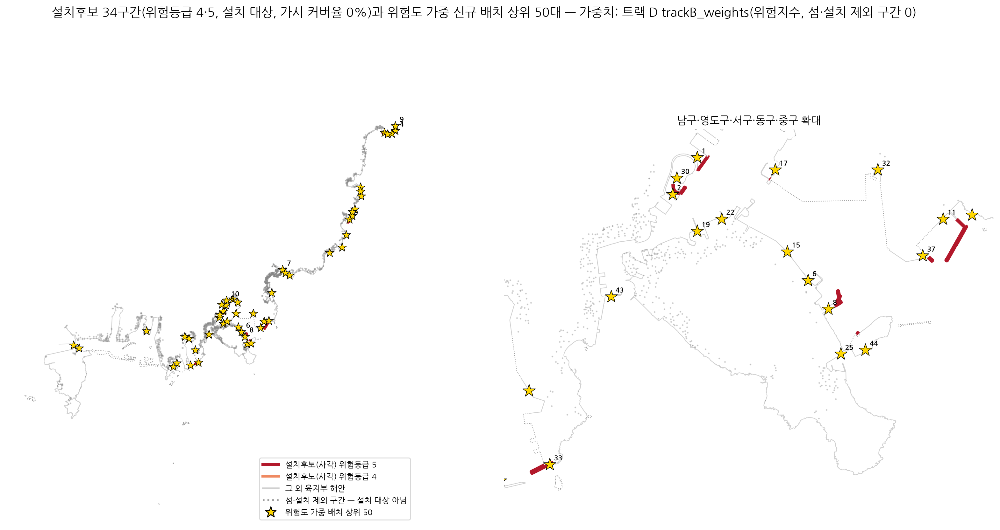

In [53]:
TOP_N = 50
!python tools/plot_viewshed_maps.py --baseline original_360 --top {TOP_N} 2>&1 | grep -E 'saved|Error|Traceback|Exception'
from IPython.display import Image, display
for name in ['busan_blind_and_new_sites.png', 'zoom_강서_사하.png', 'zoom_기장.png', 'new_sites_curve.png', 'trackA_candidates_and_risk_sites.png']:
    display(Image(f'outputs/viewshed/maps/{name}', width=900))

In [54]:
# 인터랙티브 지도 (구간에 마우스를 올리면 커버율, 번호 마커는 신규 설치 순위, 섬은 회색)
from IPython.display import HTML
HTML(open('outputs/viewshed/maps/busan_blind_and_new_sites.html', encoding='utf-8').read())

## 10. 행정안전부 연안사고(EPSG:5179) 결합 및 상위 50개 후보지 촬영방향 3분류 시각화

In [55]:
# ==============================================================================
# [추가 셀]
# ==============================================================================
import geopandas as gpd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
from pathlib import Path
import folium

로드된 부산 연안사고 데이터: 2138건 (경로: /home/alsgu/datory_work/부산전체_행정안전부_연안사고.csv, 좌표변환 EPSG:3857 -> EPSG:5186 완료)
사용한 후보지 파일: outputs/viewshed/new_sites_ranked_trackB_weights.csv

[상위 50개 CCTV 추천 장소 촬영 방향 분류 집계]


,후보지 개수
camera_direction_type,
① 해안 필수 직시형 (바다·테트라포드 고정),33
② 해안·내륙 복합형 (PTZ 양방향 전환),12
③ 내륙·진입로 감시형 (해안 직시 불필요),5


분류 테이블 저장 완료: outputs/viewshed/top50_sites_direction_classified.csv


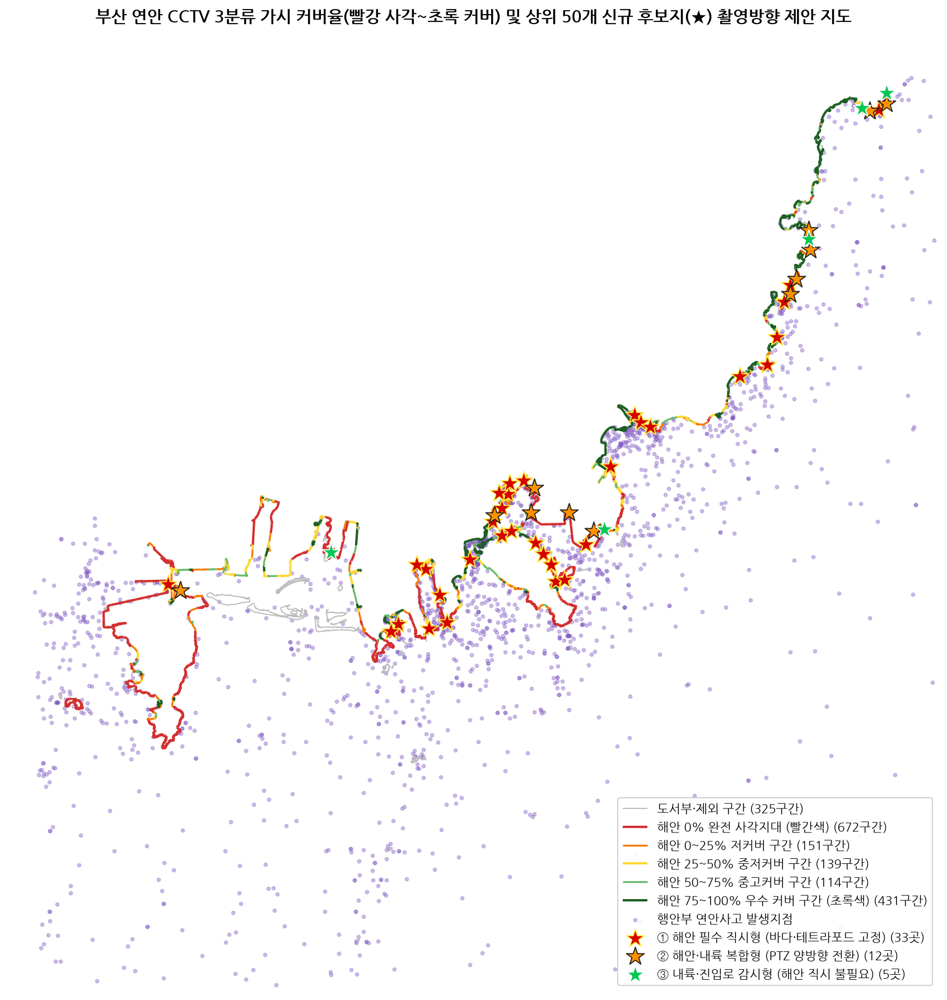

통합 지도 이미지 저장 완료: outputs/viewshed/maps/busan_top50_direction_classified.png


In [56]:
import os
from pathlib import Path
if Path.cwd().name != 'DatoryLab_trackB_2' and Path('/home/alsgu/datory_work/DatoryLab_trackB_2').exists():
    os.chdir('/home/alsgu/datory_work/DatoryLab_trackB_2')

# 한글 폰트 설정
plt.rcParams['font.family'] = 'NanumGothic'
plt.rcParams['axes.unicode_minus'] = False

# 1. 프로젝트 루트(또는 현재 작업 폴더)의 행정안전부 연안사고 CSV 불러오기 및 좌표(-> EPSG:5186) 변환
ROOT_DIR = Path('/home/alsgu/datory_work')
csv_candidates = [
    ROOT_DIR / '부산전체_행정안전부_연안사고.csv',
    Path('부산전체_행정안전부_연안사고.csv'),
    Path('../부산전체_행정안전부_연안사고.csv'),
]
acc_csv_path = next((p for p in csv_candidates if p.exists()), csv_candidates[0])

df_acc = None
for enc in ('cp949', 'euc-kr', 'utf-8-sig', 'utf-8'):
    try:
        df_acc = pd.read_csv(acc_csv_path, encoding=enc)
        break
    except UnicodeDecodeError:
        continue

# 한글 헤더가 있든 없든(영문 헤더가 첫 행이든) 동일하게 동작하도록 영문 컬럼명 -> 한글 컬럼명 표준화
col_map = {
    'objt_id': 'OBJECTID',
    'acdn_lc_cn': '사고위치내용',
    'lon': '경도',
    'polc_nm': '해경서명',
    'occu_mt': '발생월',
    'occu_ca_de': '발생원인상세',
    'occu_ty_cd': '발생유형코드',
    'occu_ty': '발생유형',
    'occu_year': '발생년',
    'occu_de': '발생일',
    'x': 'X좌표',
    'y': 'Y좌표',
    'occu_date': '발생년월일',
    'occu_lc': '발생위치',
    'wether_sn': '기상상태',
    'lat': '위도',
    'occu_tm': '발생시간',
}
df_acc = df_acc.rename(columns={k: v for k, v in col_map.items() if k in df_acc.columns and v not in df_acc.columns})

# 영문 부제목 행(objt_id, x, y 등)이 데이터 행에 섞여 있는 경우도 제거되도록 숫자형 변환 후 결측 제거
df_acc['X좌표'] = pd.to_numeric(df_acc['X좌표'], errors='coerce')
df_acc['Y좌표'] = pd.to_numeric(df_acc['Y좌표'], errors='coerce')
df_acc = df_acc.dropna(subset=['X좌표', 'Y좌표']).copy()

# 좌표계 판별 (실제 CSV의 X좌표 ~14,366,000은 EPSG:3857, ~1,100,000은 EPSG:5179) -> 분석 표준 좌표계 EPSG:5186 변환
src_crs = 'EPSG:3857' if df_acc['X좌표'].median() > 2_000_000 else 'EPSG:5179'
gdf_acc = gpd.GeoDataFrame(
    df_acc,
    geometry=gpd.points_from_xy(df_acc['X좌표'], df_acc['Y좌표']),
    crs=src_crs
).to_crs('EPSG:5186')

print(f"로드된 부산 연안사고 데이터: {len(gdf_acc)}건 (경로: {acc_csv_path}, 좌표변환 {src_crs} -> EPSG:5186 완료)")

# 2. 트랙 B 해안선 구간(1,832개) 및 상위 50개 신규 설치 후보지 데이터 로드
seg_df = pd.read_csv('outputs/trackD/segments.csv', encoding='utf-8-sig')
if 'coverage_pct_conservative' not in seg_df.columns and 'view_coverage_pct_conservative' in seg_df.columns:
    seg_df['coverage_pct_conservative'] = seg_df['view_coverage_pct_conservative']
if 'island_flag' not in seg_df.columns:
    if '육지부' in seg_df.columns:
        seg_df['island_flag'] = (~seg_df['육지부'].astype(bool)).astype(int)
    elif 'GRP_ISL' in seg_df.columns:
        seg_df['island_flag'] = (seg_df['GRP_ISL'] == 2).astype(int)
if 'coast_type' not in seg_df.columns and '해안유형' in seg_df.columns:
    seg_df['coast_type'] = seg_df['해안유형']
if 'risk_index' not in seg_df.columns and '위험지수' in seg_df.columns:
    seg_df['risk_index'] = seg_df['위험지수']
if 'SGG_NAM' not in seg_df.columns and '구' in seg_df.columns:
    seg_df['SGG_NAM'] = seg_df['구']

gpkg_path = 'data/raw/cctv_reanalysis/coastal_safety_busan.gpkg'
coast_gdf = gpd.read_file(gpkg_path, layer='coastline_monitoring_segments').to_crs('EPSG:5186')

# 상위 50개 후보지 파일 탐색 (위험도 가중 배치 우선, 없으면 균등 배치)
top50_candidates = (
    list(Path('outputs/viewshed').glob('*new_sites*ranked*trackB_weights*.csv')) +
    list(Path('outputs/viewshed').glob('*new_sites*ranked*.csv')) +
    list(Path('outputs/viewshed').glob('*new_sites*trackB_weights*.csv')) +
    list(Path('outputs/viewshed').glob('*new_sites*.csv'))
)

# 후보지 좌표가 담긴 CSV 로드 (rank <= 50, 3분류 기본 반영 original_360 기준)
sites_df = None
for p in top50_candidates:
    tmp = pd.read_csv(p, encoding='utf-8-sig')
    if 'main_segment_id' in tmp.columns and 'segment_id' not in tmp.columns:
        tmp['segment_id'] = tmp['main_segment_id']
    if {'x_5186', 'y_5186'}.issubset(tmp.columns) and not {'x', 'y'}.issubset(tmp.columns):
        tmp['x'] = tmp['x_5186']
        tmp['y'] = tmp['y_5186']
    if {'segment_id', 'rank'}.issubset(tmp.columns) or {'x', 'y'}.issubset(tmp.columns):
        sites_df = tmp
        print(f"사용한 후보지 파일: {p}")
        break

# 만약 별도 좌표 CSV가 없다면 segments.csv에서 우선순위 상위 50개 추출
if sites_df is not None and 'baseline' in sites_df.columns:
    top50 = sites_df[sites_df['baseline'] == 'original_360'].nsmallest(50, 'rank').copy()
elif sites_df is not None and 'rank' in sites_df.columns:
    top50 = sites_df.nsmallest(50, 'rank').copy()
else:
    # segments.csv의 위험지수 상위 및 사각지대(보수적 커버율 0) 기준 상위 50개 추출
    blind_segs = seg_df[(seg_df['coverage_pct_conservative'] == 0) & (seg_df['island_flag'] == 0)].copy()
    top50 = blind_segs.nlargest(50, 'risk_index').copy()

# 후보지 지오메트리 구성 (EPSG:5186)
if {'x', 'y'}.issubset(top50.columns):
    gdf_top50 = gpd.GeoDataFrame(top50, geometry=gpd.points_from_xy(top50['x'], top50['y']), crs='EPSG:5186')
elif {'lon', 'lat'}.issubset(top50.columns):
    gdf_top50 = gpd.GeoDataFrame(top50, geometry=gpd.points_from_xy(top50['lon'], top50['lat']), crs='EPSG:4326').to_crs('EPSG:5186')
else:
    # segment_id 기준으로 해안선 중심점 결합
    top50_merged = top50.merge(coast_gdf[['segment_id', 'geometry']], on='segment_id', how='left')
    top50_merged['geometry'] = top50_merged['geometry'].centroid
    gdf_top50 = gpd.GeoDataFrame(top50_merged, geometry='geometry', crs='EPSG:5186')

# 구간 속성(해안유형 등) 결합
if 'segment_id' in gdf_top50.columns and 'coast_type' not in gdf_top50.columns:
    merge_cols = ['segment_id'] + [c for c in ['coast_type', 'CAT_COA', 'risk_index', 'SGG_NAM'] if c in seg_df.columns and c not in gdf_top50.columns]
    gdf_top50 = gdf_top50.merge(seg_df[merge_cols], on='segment_id', how='left')

# 3. 반경 500m 내 연안사고 공간 결합 및 촬영 방향 3분류 로직 적용
human_acc_types = ['추락', '익수', '고립', '실종', '표류', '전복', '침몰', '좌초', '좌초/좌주', '충돌', '조난', '인명사상', '작업 중 인명사상']
acc_type_col = '발생유형' if '발생유형' in gdf_acc.columns else '사고종류'

directions = []
acc_counts_500m = []
human_acc_counts = []

for idx, row in gdf_top50.iterrows():
    buf_500 = row.geometry.buffer(500) # 후보지 반경 500m 버퍼
    nearby_acc = gdf_acc[gdf_acc.geometry.within(buf_500)]

    total_cnt = len(nearby_acc)
    # 단순 기관고장 외 직접적 해상/추락 위험 사고 건수
    severe_cnt = len(nearby_acc[
        nearby_acc[acc_type_col].isin(human_acc_types) |
        nearby_acc['발생위치'].astype(str).str.replace(' ', '').eq('항계내')
    ])

    c_type = str(row.get('coast_type', row.get('CAT_COA', '')))

    # [3분류 판정 기준]
    # 1) 반경 500m 사고 3건 이상이거나, 고위험 사고 2건 이상 + 암벽/방파제/인공 지형 -> 해안 구역 필수 직시
    if total_cnt >= 3 or (severe_cnt >= 2 and any(k in c_type for k in ['방파제', '암벽', '테트라포드', '갯바위', '인공'])):
        d_label = '① 해안 필수 직시형 (바다·테트라포드 고정)'
    # 2) 반경 500m 사고 1~2건 존재하거나 항포구/해변 지형 -> 해안+내륙 복합 전환형(PTZ)
    elif total_cnt >= 1 or any(k in c_type for k in ['항포구', '해수욕장', '모래']):
        d_label = '② 해안·내륙 복합형 (PTZ 양방향 전환)'
    # 3) 반경 500m 내 해상사고 이력 0건 -> 내륙 진입로/배후 관문 감시형
    else:
        d_label = '③ 내륙·진입로 감시형 (해안 직시 불필요)'

    acc_counts_500m.append(total_cnt)
    human_acc_counts.append(severe_cnt)
    directions.append(d_label)

gdf_top50['acc_count_500m'] = acc_counts_500m
gdf_top50['severe_acc_500m'] = human_acc_counts
gdf_top50['camera_direction_type'] = directions

print("\n[상위 50개 CCTV 추천 장소 촬영 방향 분류 집계]")
display(gdf_top50['camera_direction_type'].value_counts().to_frame('후보지 개수'))

# 분류 결과 CSV 저장
out_csv = Path('outputs/viewshed/top50_sites_direction_classified.csv')
out_csv.parent.mkdir(parents=True, exist_ok=True)
gdf_top50.drop(columns='geometry').to_csv(out_csv, encoding='utf-8-sig', index=False)
print(f"분류 테이블 저장 완료: {out_csv}")

# 4. 부산 해안선 구간별 가시 커버율(기존 CCTV 3분류 반영: 빨간색 사각지대 ~ 초록색 커버 구간) + 3분류 별 마크(★) 통합 지도 시각화
fig, ax = plt.subplots(figsize=(14, 12), dpi=150)

# 기존 1,782개 CCTV 3분류 기준이 반영된 해안선 구간 가시 커버율(view_coverage_pct_original) 결합
cov_col = 'view_coverage_pct_original' if 'view_coverage_pct_original' in seg_df.columns else 'coverage_pct_conservative'
coast_merged = coast_gdf.merge(seg_df[['segment_id', cov_col, 'coverage_pct_conservative', 'island_flag']], on='segment_id', how='left')
coast_merged[cov_col] = coast_merged[cov_col].fillna(0.0)

island_coast = coast_merged[coast_merged['island_flag'] == 1]
land_coast = coast_merged[coast_merged['island_flag'] == 0].copy()

# 빨간색(0% 완전 사각지대) ~ 주황/노랑(부분 커버) ~ 초록색(커버 구간) 5단계 구간 색상 설정
cov_bins = [-0.1, 0.0, 25.0, 50.0, 75.0, 100.0]
cov_labels = [
    '0% 완전 사각지대 (빨간색)',
    '0~25% 저커버 구간',
    '25~50% 중저커버 구간',
    '50~75% 중고커버 구간',
    '75~100% 우수 커버 구간 (초록색)'
]
cov_colors = ['#D32F2F', '#F57C00', '#FDD835', '#66BB6A', '#1B5E20']
land_coast['cov_class'] = pd.cut(land_coast[cov_col], bins=cov_bins, labels=cov_labels)

island_coast.plot(ax=ax, color='#BDBDBD', linewidth=1.0, label=f'도서부·제외 구간 ({len(island_coast)}구간)')
for clabel, ccolor in zip(cov_labels, cov_colors):
    sub_c = land_coast[land_coast['cov_class'] == clabel]
    if len(sub_c) > 0:
        lw = 2.0 if '0%' in clabel else 1.6
        sub_c.plot(ax=ax, color=ccolor, linewidth=lw, label=f'해안 {clabel} ({len(sub_c)}구간)')

# 부산 해안 범위 내 연안사고 위치 연한 점으로 표시 (원거리 외해 이상치로 인한 축 왜곡 방지)
minx, miny, maxx, maxy = coast_gdf.total_bounds
pad = 3000
gdf_acc_busan = gdf_acc.cx[minx - pad:maxx + pad, miny - pad:maxy + pad]
gdf_acc_busan.plot(ax=ax, color='#7E57C2', markersize=8, alpha=0.35, label='행안부 연안사고 발생지점')

# 3가지 촬영 방향별 별 마크(★) 색상 구분 플로팅
color_map = {
    '① 해안 필수 직시형 (바다·테트라포드 고정)': ('#D50000', '#FFEB3B'), # 진한 빨강 별 (노란 테두리)
    '② 해안·내륙 복합형 (PTZ 양방향 전환)': ('#FF9100', '#212121'),     # 주황/황금색 별 (검은 테두리)
    '③ 내륙·진입로 감시형 (해안 직시 불필요)': ('#00C853', '#FFFFFF')    # 초록색 별 (흰 테두리)
}

for dtype, (facecolor, edgecolor) in color_map.items():
    sub = gdf_top50[gdf_top50['camera_direction_type'] == dtype]
    if len(sub) > 0:
        ax.scatter(
            sub.geometry.x, sub.geometry.y,
            marker='*', s=260, c=facecolor, edgecolors=edgecolor, linewidths=0.9,
            zorder=10, label=f"{dtype} ({len(sub)}곳)"
        )

ax.set_xlim(minx - pad, maxx + pad)
ax.set_ylim(miny - pad, maxy + pad)
ax.set_title('부산 연안 CCTV 3분류 가시 커버율(빨강 사각~초록 커버) 및 상위 50개 신규 후보지(★) 촬영방향 제안 지도', fontsize=14.5, fontweight='bold', pad=15)
ax.set_axis_off()
ax.legend(loc='lower right', frameon=True, facecolor='white', framealpha=0.9, fontsize=10.5)

plt.tight_layout()
map_out_path = Path('outputs/viewshed/maps/busan_top50_direction_classified.png')
map_out_path.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(map_out_path, dpi=200, bbox_inches='tight')
plt.show()
print(f"통합 지도 이미지 저장 완료: {map_out_path}")

# 5. 인터랙티브 지도(busan_blind_and_new_sites.html)도 최신 연안사고 데이터 기준으로 함께 갱신
import sys
if 'tools' not in sys.path:
    sys.path.insert(0, 'tools')
import importlib
import plot_viewshed_maps as _pvm
importlib.reload(_pvm)
_seg, _sites, _obs = _pvm.load('original_360', 50)
_html_out = _pvm.interactive_map(_seg, _sites, _obs, 'original_360', 50)
print(f"인터랙티브 지도 HTML 갱신 완료: {_html_out}")

## 11. 결과 저장 (루트 디렉토리 `trackB_2_results` 폴더 정리)


In [57]:
import shutil
from pathlib import Path

# 루트 디렉토리(/home/alsgu/datory_work) 기준 결과 정리 폴더 설정
ROOT_DIR = Path('/home/alsgu/datory_work') if Path('/home/alsgu/datory_work').exists() else Path.cwd().parent
SRC_OUT = ROOT_DIR / 'DatoryLab_trackB_2' / 'outputs'
if not SRC_OUT.exists():
    SRC_OUT = Path('outputs')

RESULT_DIR = ROOT_DIR / 'trackB_2_results'
MAPS_DIR = RESULT_DIR / 'maps'
CSV_DIR = RESULT_DIR / 'csv'
TRACKD_DIR = RESULT_DIR / 'trackD'

for d in (MAPS_DIR, CSV_DIR, TRACKD_DIR):
    d.mkdir(parents=True, exist_ok=True)

# 1) 지도 파일(HTML, PNG) 정리 -> trackB_2_results/maps/
for p in sorted((SRC_OUT / 'viewshed' / 'maps').glob('*')):
    if p.is_file():
        shutil.copy2(p, MAPS_DIR / p.name)

# 2) 주요 분석 결과 CSV 정리 -> trackB_2_results/csv/
csv_targets = list(SRC_OUT.glob('*.csv')) + list((SRC_OUT / 'viewshed').glob('*.csv')) + list((SRC_OUT / 'cctv_reanalysis').glob('*.csv'))
for p in sorted(csv_targets):
    if p.is_file():
        shutil.copy2(p, CSV_DIR / p.name)

# 3) 트랙 D 연동 파일 정리 -> trackB_2_results/trackD/
for p in sorted((SRC_OUT / 'trackD').glob('*')):
    if p.is_file():
        shutil.copy2(p, TRACKD_DIR / p.name)

# 4) 전체 outputs 백업 압축파일 생성 -> trackB_2_results/trackB_2_outputs.zip
archive = shutil.make_archive(str(RESULT_DIR / 'trackB_2_outputs'), 'zip', str(SRC_OUT))

print(f'✅ 결과 정리 완료: {RESULT_DIR}')
for sub_name, sub_dir in [('maps (지도)', MAPS_DIR), ('csv (분석표)', CSV_DIR), ('trackD (트랙D 연동)', TRACKD_DIR)]:
    files = sorted(sub_dir.glob('*'))
    print(f'  📁 {sub_name}: {len(files)}개 파일 -> {sub_dir}')
    for f in files:
        print(f'     - {f.name} ({f.stat().st_size / 1024:.1f} KB)')
print(f'  📦 전체 백업 압축파일: {archive} ({Path(archive).stat().st_size / (1024*1024):.2f} MB)')


✅ 결과 정리 완료: /home/alsgu/datory_work/trackB_2_results
  📁 maps (지도): 7개 파일 -> /home/alsgu/datory_work/trackB_2_results/maps
     - busan_blind_and_new_sites.html (8107.9 KB)
     - busan_blind_and_new_sites.png (288.8 KB)
     - busan_top50_direction_classified.png (562.1 KB)
     - new_sites_curve.png (108.7 KB)
     - trackA_candidates_and_risk_sites.png (415.7 KB)
     - zoom_강서_사하.png (223.3 KB)
     - zoom_기장.png (132.8 KB)
  📁 csv (분석표): 20개 파일 -> /home/alsgu/datory_work/trackB_2_results/csv
     - cctv_coverage_by_district.csv (0.8 KB)
     - cctv_deduplication_report.csv (0.2 KB)
     - cctv_integrated_locations.csv (3236.0 KB)
     - cctv_integrated_locations_fov.csv (3589.8 KB)
     - cctv_reanalysis_summary.csv (0.7 KB)
     - input_trackB_segments.csv (126.8 KB)
     - new_sites_curve.csv (1.0 KB)
     - new_sites_curve_trackB_weights.csv (1.2 KB)
     - new_sites_ranked.csv (40.2 KB)
     - new_sites_ranked_trackB_weights.csv (40.4 KB)
     - new_sites_top50_by_district.csv